# Asociación entre características sociodemográficas y supervivencia en el Titanic: un análisis exploratorio de datos reproducible

**MCDI503 · Exploración Inteligente para la Ciencia de Datos · Sumativa 1 (Fase 1)**

## I. Identificación del proyecto

| Campo | Detalle |
|---|---|
| Curso | MCDI503 Exploración Inteligente para la Ciencia de Datos (UNAB) |
| Equipo | Grupo 4: Felipe Díaz Toro, Pablo Ríos Passteni, Guillermo Subiabre Chacón y Ninoska Yévenes Hernández |
| Conjunto de datos | `titanic` del repositorio `seaborn-data` (Waskom, s. f.), leído desde una copia local verificada con SHA-256 (`data/raw/titanic.csv`) y, si no está disponible, desde Seaborn (`sns.load_dataset`) como respaldo (ver sección III.1) |
| Propósito general | Identificar, mediante un EDA documentado y reproducible, qué características de los pasajeros se asocian con la supervivencia, y dejar un diagnóstico de calidad del dataset como base para las fases siguientes. |
| Fecha de entrega | 29 de noviembre de 2026 |

### Configuración del entorno y reproducibilidad
Esta celda deja registradas las versiones con las que se ejecutó el análisis y fija la semilla aleatoria. Si alguien reproduce el notebook con otras versiones, puede comparar con esta salida.

In [1]:
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

print("Python    :", sys.version.split()[0])
print("numpy     :", np.__version__)
print("pandas    :", pd.__version__)
print("seaborn   :", sns.__version__)
print("matplotlib:", matplotlib.__version__)
print("Semilla   :", SEED)

Python    : 3.13.7
numpy     : 2.5.3
pandas    : 3.0.5
seaborn   : 0.13.2
matplotlib: 3.11.1
Semilla   : 42


## II. Contexto y objetivo exploratorio

**Contexto.** El hundimiento del Titanic (abril de 1912) es un caso histórico documentado con registros individuales de pasajeros. Estos registros permiten estudiar cómo se relacionan las características personales y de viaje con la supervivencia. El caso es adecuado para esta fase porque presenta valores faltantes, variables de distinto tipo y posibles valores atípicos.

**Objetivo exploratorio.** Examinar, mediante un análisis exploratorio de datos descriptivo y reproducible, la asociación entre la supervivencia de los pasajeros del Titanic y un conjunto de características sociodemográficas y de viaje (sexo, edad, clase del pasaje y acompañamiento familiar), evaluando previamente la calidad de los datos y documentando las decisiones de preparación adoptadas. La tarifa se describe en la exploración preliminar y el puerto de embarque se usa en el diagnóstico de faltantes. Este alcance se acota respecto del plan de la Formativa 1: la tarifa y el puerto no se contrastan con la supervivencia en este avance y quedan para una fase posterior.

**Criterio de comparación.** Siguiendo el enfoque de EDA mínimo viable del curso (Paraíso, 2026), cada comparación muestra la tasa de supervivencia (%) y el número de pasajeros (n) de cada grupo, y las diferencias se expresan en puntos porcentuales. No se estiman efectos ni se atribuyen causas.

**Preguntas exploratorias iniciales**
1. ¿Cómo se distribuyen la edad, la tarifa y la clase de los pasajeros, y hay valores atípicos? *(sección IV)* **Cómo se responderá:** tabla con n válido, media, desviación estándar, mediana, cuartiles y extremos; histogramas; frecuencias por clase; valores atípicos con la regla de 1,5 × RIC.
2. ¿Cambia la supervivencia según el sexo y la clase del pasaje? *(sección VI)* **Cómo se responderá:** tabla con la tasa de supervivencia (%) y el n de cada grupo sexo × clase, gráfico de barras agrupadas y diferencias en puntos porcentuales.
3. ¿Cómo se relaciona la edad con la supervivencia? *(sección VI)* **Cómo se responderá:** resumen de la edad (n, media, mediana, cuartiles y desviación) de quienes sobrevivieron y no sobrevivieron, y diagrama de caja.
4. ¿Viajar con familiares registrados (`sibsp`, `parch`, `alone`) se asocia con sobrevivir? *(secciones IV y VI.3)* **Cómo se responderá:** frecuencias de acompañamiento en IV; tasa de supervivencia y n por tamaño del grupo familiar (solo, 2 a 4, 5 o más) y por sexo en VI.3.
5. ¿Los faltantes de `age` y `deck` se concentran en ciertos grupos? *(sección V)* **Cómo se responderá:** porcentaje de faltantes dentro de cada grupo (clase, sexo, supervivencia y puerto), con el n de cada grupo.

## III. Carga y revisión inicial de datos
En esta sección se carga el dataset, se verifica que corresponda a la versión de referencia del grupo y se describe su estructura y estado general (tipos, faltantes, filas idénticas y consistencia). Aquí solo se **diagnostica**: las decisiones sobre lo encontrado se toman en la sección V.

#### III.1 Fuente, versión y carga

| Campo | Valor |
|---|---|
| Fuente | `titanic.csv` del repositorio `mwaskom/seaborn-data` (Waskom, s. f.) |
| URL de descarga | https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv |
| Copia local | `data/raw/titanic.csv` (no se modifica; está excluida del control de versiones) |
| Respaldo | `sns.load_dataset("titanic")`, solo si no existe la copia local; reconstruye el mismo CSV (mismo SHA-256) |
| Fecha de descarga | 23 de noviembre de 2026 |
| Tamaño | 57.018 bytes |
| SHA-256 | `81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2` |

- **Pregunta:** ¿los datos con los que trabajamos son exactamente la versión de referencia del grupo?
- **Acción:** se calcula el hash SHA-256 del contenido (copia local o respaldo de Seaborn), se compara con el valor registrado y se carga con `pandas.read_csv`.
- **Decisión y por qué:** se prioriza la copia local fija porque `sns.load_dataset("titanic")` descarga la versión vigente del repositorio, que podría cambiar, y porque permite ejecutar sin conexión. Si no existe la copia local, se usa Seaborn como respaldo y se verifica el mismo hash, de modo que ambas rutas entregan exactamente los mismos datos. Si el hash no coincide, el notebook se detiene.

In [2]:
import hashlib
import io
from pathlib import Path

RUTA_DATOS = Path("data/raw/titanic.csv")
if Path.cwd().name == "notebooks":
    RUTA_DATOS = Path("..") / RUTA_DATOS
SHA256_ESPERADO = "81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2"

if RUTA_DATOS.is_file():
    contenido = RUTA_DATOS.read_bytes()
    fuente = f"copia local ({RUTA_DATOS.name})"
else:
    # Respaldo: sin copia local (por ejemplo, otro equipo) se carga desde seaborn-data.
    contenido = sns.load_dataset("titanic").to_csv(index=False).encode("utf-8")
    fuente = "seaborn (sns.load_dataset), respaldo"

sha256 = hashlib.sha256(contenido).hexdigest()
if sha256 != SHA256_ESPERADO:
    raise ValueError(f"El CSV de {fuente} difiere de la referencia. SHA-256 obtenido: {sha256}")

titanic = pd.read_csv(io.BytesIO(contenido))
print("Fuente       :", fuente)
print("SHA-256      :", sha256)
print("Dimensiones  :", titanic.shape)
titanic.head()

Fuente       : copia local (titanic.csv)
SHA-256      : 81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2
Dimensiones  : (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


#### III.2 Estructura y tipos de variables
- **Pregunta:** ¿qué representa cada fila y de qué tipo es cada variable?
- **Acción:** se revisa `info()` y se construye una tabla con el tipo de dato, el número de valores distintos, los faltantes y un ejemplo por columna.
- **Decisión y por qué:** además del tipo de dato de pandas, cada variable se clasifica según su tipo analítico (binaria, nominal, ordinal, discreta o continua), porque ese tipo determina el resumen y el gráfico adecuados en las secciones siguientes.

In [3]:
titanic.info()

estructura = pd.DataFrame({
    "dtype": titanic.dtypes.astype(str),
    "n_unicos": titanic.nunique(dropna=True),
    "n_faltantes": titanic.isna().sum(),
    "pct_faltantes": (titanic.isna().mean() * 100).round(1),
    "ejemplo": titanic.apply(lambda s: s.dropna().iloc[0]),
})
estructura

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


,dtype,n_unicos,n_faltantes,pct_faltantes,ejemplo
survived,int64,2,0,0.0,0
pclass,int64,3,0,0.0,3
sex,str,2,0,0.0,male
age,float64,88,177,19.9,22.0
sibsp,int64,7,0,0.0,1
parch,int64,7,0,0.0,0
fare,float64,248,0,0.0,7.25
embarked,str,3,2,0.2,S
class,str,3,0,0.0,Third
who,str,3,0,0.0,man


**Diccionario de variables**

| Variable | Descripción | Tipo analítico | Observación |
|---|---|---|---|
| `survived` | Sobrevivió (0 = no, 1 = sí) | Binaria (variable objetivo) | |
| `pclass` | Clase del pasaje (1, 2, 3) | Categórica ordinal | Se almacena como entero |
| `sex` | Sexo del pasajero | Categórica nominal | |
| `age` | Edad en años | Numérica continua | Con faltantes |
| `sibsp` | N.º de hermanos o cónyuges a bordo | Numérica discreta | |
| `parch` | N.º de padres o hijos a bordo | Numérica discreta | |
| `fare` | Tarifa pagada | Numérica continua | |
| `embarked` | Puerto de embarque (C, Q, S) | Categórica nominal | Con faltantes |
| `deck` | Cubierta (A–G) | Categórica nominal | Con faltantes |
| `class` | Clase en texto | Redundante con `pclass` | Se verifica en III.5 |
| `who` | Hombre, mujer o niño | Derivada de `sex` y `age` | Se verifica en III.5 |
| `adult_male` | Es hombre adulto | Derivada de `who` | Se verifica en III.5 |
| `embark_town` | Puerto en texto | Redundante con `embarked` | Se verifica en III.5 |
| `alive` | Sobrevivió en texto | Redundante con `survived` | Se verifica en III.5 |
| `alone` | Viajaba sin familiares | Derivada de `sibsp` y `parch` | Se verifica en III.5 |

- **Resultado:** cada fila corresponde a un pasajero; hay 891 filas y 15 columnas (4 enteras, 2 decimales, 7 de texto y 2 booleanas). Con pandas 3 las columnas de texto se leen con el tipo `str`. `pclass` está almacenada como número, pero conceptualmente es ordinal, lo que conviene tener en cuenta al resumirla.

#### III.3 Valores faltantes
- **Pregunta:** ¿cuántos valores faltan y en qué variables?
- **Acción:** se cuentan los faltantes por columna y su porcentaje sobre el total de filas.
- **Decisión y por qué:** se reportan solo las columnas con faltantes; su patrón (pregunta 5) se analiza en la sección V, antes de decidir cómo tratarlos.

In [4]:
faltantes = (
    titanic.isna().sum().to_frame("n_faltantes")
    .assign(pct_faltantes=lambda d: (d["n_faltantes"] / len(titanic) * 100).round(1))
    .query("n_faltantes > 0")
    .sort_values("n_faltantes", ascending=False)
)
faltantes

,n_faltantes,pct_faltantes
deck,688,77.2
age,177,19.9
embarked,2,0.2
embark_town,2,0.2


- **Resultado:** faltan datos en cuatro columnas: `deck` (688; 77,2 %), `age` (177; 19,9 %), `embarked` y `embark_town` (2 cada una; 0,2 %, en los mismos dos registros). La magnitud en `deck` sugiere que su uso analítico será limitado.

#### III.4 Filas idénticas
- **Pregunta:** ¿existen filas idénticas y cómo son?
- **Acción:** se cuentan las filas idénticas en las 15 columnas y se caracterizan los grupos que forman.
- **Decisión y por qué:** en esta etapa solo se cuantifican; la decisión se toma en la sección V, porque el dataset no tiene un identificador de pasajero que permita confirmar si corresponden a un mismo pasajero.

In [5]:
mask_dup = titanic.duplicated(keep=False)
grupos_dup = titanic[mask_dup].groupby(list(titanic.columns), dropna=False).size()

print("Filas idénticas (sin contar la primera aparición) :", titanic.duplicated().sum())
print("Filas involucradas en algún grupo idéntico        :", mask_dup.sum())
print("Grupos de filas idénticas                         :", len(grupos_dup))
print("Tamaño del grupo más grande                       :", grupos_dup.max())
print("Filas involucradas sin edad registrada            :", titanic.loc[mask_dup, "age"].isna().sum())
print("\nFilas involucradas por clase:")
print(titanic.loc[mask_dup, "pclass"].value_counts().sort_index().to_string())

Filas idénticas (sin contar la primera aparición) : 107
Filas involucradas en algún grupo idéntico        : 160
Grupos de filas idénticas                         : 53
Tamaño del grupo más grande                       : 13
Filas involucradas sin edad registrada            : 93

Filas involucradas por clase:
pclass
1      4
2     31
3    125


- **Resultado:** hay 107 filas idénticas; en total, 160 filas forman parte de 53 grupos idénticos (el mayor reúne 13 filas). La mayoría corresponde a tercera clase (125 de 160) y a registros sin edad (93 de 160), es decir, perfiles muy comunes con pocas columnas distintivas.

#### III.5 Consistencia, dominios y rangos
- **Pregunta:** ¿las columnas derivadas son coherentes con sus columnas de origen? ¿hay categorías incoherentes o valores fuera de rango?
- **Acción:** se verifican las equivalencias entre columnas, se listan las categorías de las variables de texto y se revisan mínimos y máximos de las numéricas.
- **Decisión y por qué:** se comprueban las equivalencias con código en vez de suponerlas, porque de ese resultado depende la decisión de eliminar columnas redundantes en la sección V.

In [6]:
inicial_puerto = titanic["embark_town"].str[0]
chequeos = pd.Series({
    "class equivale a pclass": titanic["class"].map({"First": 1, "Second": 2, "Third": 3}).eq(titanic["pclass"]).all(),
    "alive equivale a survived": titanic["alive"].map({"no": 0, "yes": 1}).eq(titanic["survived"]).all(),
    "embark_town equivale a embarked": inicial_puerto.fillna("-").eq(titanic["embarked"].fillna("-")).all(),
    "alone equivale a sibsp + parch == 0": titanic["alone"].eq(titanic["sibsp"] + titanic["parch"] == 0).all(),
    "adult_male equivale a who == 'man'": titanic["adult_male"].eq(titanic["who"] == "man").all(),
    "who == 'child' equivale a age < 16": (titanic["who"] == "child").eq(titanic["age"] < 16).all(),
}, name="se_cumple")
display(chequeos.to_frame())

print("Categorías de las variables de texto:")
for col in ["sex", "embarked", "deck", "who"]:
    print(f"  {col}: {titanic[col].value_counts(dropna=False).to_dict()}")

print("\nRangos de las variables numéricas:")
display(titanic[["age", "fare", "sibsp", "parch"]].agg(["min", "max"]))

edad = titanic["age"].dropna()
print("Edades menores de 1 año (con decimales):", (edad < 1).sum())
print("Edades terminadas en ,5 (desde 1 año)  :", ((edad >= 1) & (edad % 1 == 0.5)).sum())
print("Pasajeros con fare == 0                :", (titanic["fare"] == 0).sum())
print("Sin edad, clasificados por who como    :", titanic.loc[titanic["age"].isna(), "who"].value_counts().to_dict())

,se_cumple
class equivale a pclass,True
alive equivale a survived,True
embark_town equivale a embarked,True
alone equivale a sibsp + parch == 0,True
adult_male equivale a who == 'man',True
who == 'child' equivale a age < 16,True


Categorías de las variables de texto:
  sex: {'male': 577, 'female': 314}
  embarked: {'S': 644, 'C': 168, 'Q': 77, nan: 2}
  deck: {nan: 688, 'C': 59, 'B': 47, 'D': 33, 'E': 32, 'A': 15, 'F': 13, 'G': 4}
  who: {'man': 537, 'woman': 271, 'child': 83}

Rangos de las variables numéricas:


,age,fare,sibsp,parch
min,0.42,0.0000,0,0
max,80.00,512.3292,8,6


Edades menores de 1 año (con decimales): 7
Edades terminadas en ,5 (desde 1 año)  : 18
Pasajeros con fare == 0                : 15
Sin edad, clasificados por who como    : {'man': 124, 'woman': 53}


- **Resultado:** las seis equivalencias se cumplen en el 100 % de las filas, por lo que `class`, `alive`, `embark_town`, `adult_male`, `who` y `alone` no aportan información nueva. Las categorías de texto no presentan errores de escritura. Los rangos son plausibles: `age` va de 0,42 a 80 años (7 menores de un año con decimales y 18 edades terminadas en ,5), `fare` va de 0 a 512,33, y `sibsp` (máx. 8) y `parch` (máx. 6) son compatibles con familias numerosas. Quedan dos alertas: 15 pasajeros con `fare` igual a 0, que no necesariamente son errores, y que `who` asigna “man” o “woman” a los 177 pasajeros sin edad, por lo que nunca los clasifica como niños.

## IV. Exploración preliminar

Esta sección usa los datos originales cargados en III.1. Describe la supervivencia global, la edad, la tarifa y la clase (pregunta 1), revisa la anomalía de tarifa detectada en III.5 y caracteriza los acompañantes como paso previo a la comparación de supervivencia de VI.3 (pregunta 4).

- **Pregunta:** ¿Cómo se distribuyen la edad, la tarifa y la clase del pasaje? ¿Cuántos pasajeros viajaban con familiares registrados?
- **Acción:** se resumen edad y tarifa con recuentos, media, desviación estándar, mediana, cuartiles y extremos. Los histogramas muestran su distribución. Para clase y acompañamiento se presentan frecuencias, porcentajes y gráficos de barras.
- **Decisión y por qué:** se reportan los estadísticos mínimos que el apunte del curso fija para una variable numérica continua: media y mediana para la tendencia central, y desviación estándar, rango y RIC (= Q3 − Q1) para la dispersión. Comparar media con mediana permite detectar asimetría sin depender solo del gráfico. Siguiendo ese mismo enfoque de EDA mínimo viable (Paraíso, 2026), se deja visible el denominador de cada resumen. Para detectar observaciones potencialmente atípicas se marcan valores por debajo de Q1 − 1,5 × RIC o por encima de Q3 + 1,5 × RIC (Bruce et al., 2020). Se conservan para el análisis por su plausibilidad (III.5 y V.2). Para edad se usan únicamente los valores registrados. La supervivencia global se reporta primero porque es la línea base contra la cual se leen todas las tasas por grupo de la sección VI. La clase se mantiene en orden 1–2–3 y el acompañamiento familiar usa `alone`, cuya equivalencia con `sibsp + parch == 0` se verifica en III.5.

,n_válido,n_faltante,mínimo,Q1,mediana,media,Q3,máximo,RIC,desv_est,límite inferior,límite superior,n fuera de límites
age,714,177,0.42,20.12,28.00,29.7,38.0,80.00,17.88,14.53,-6.69,64.81,11
fare,891,0,0.00,7.91,14.45,32.2,31.0,512.33,23.09,49.69,-26.72,65.63,116


,n,% del total
Supervivencia (línea base),,
No sobrevivió,549,61.6
Sobrevivió,342,38.4


,n,% del total
Clase del pasaje,,
1,216,24.2
2,184,20.7
3,491,55.1


,n,% del total
Acompañamiento familiar,,
Sin familiares registrados,537,60.3
Con familiares registrados,354,39.7


Pasajeros con tarifa 0: 15 de 891
  por clase       : {1: 5, 2: 6, 3: 4}
  por sexo        : {'male': 15}
  puerto          : {'S': 15}
  viajaban solos  : 15 de 15
  tasa de supervivencia: 6.7 % (1 de 15)


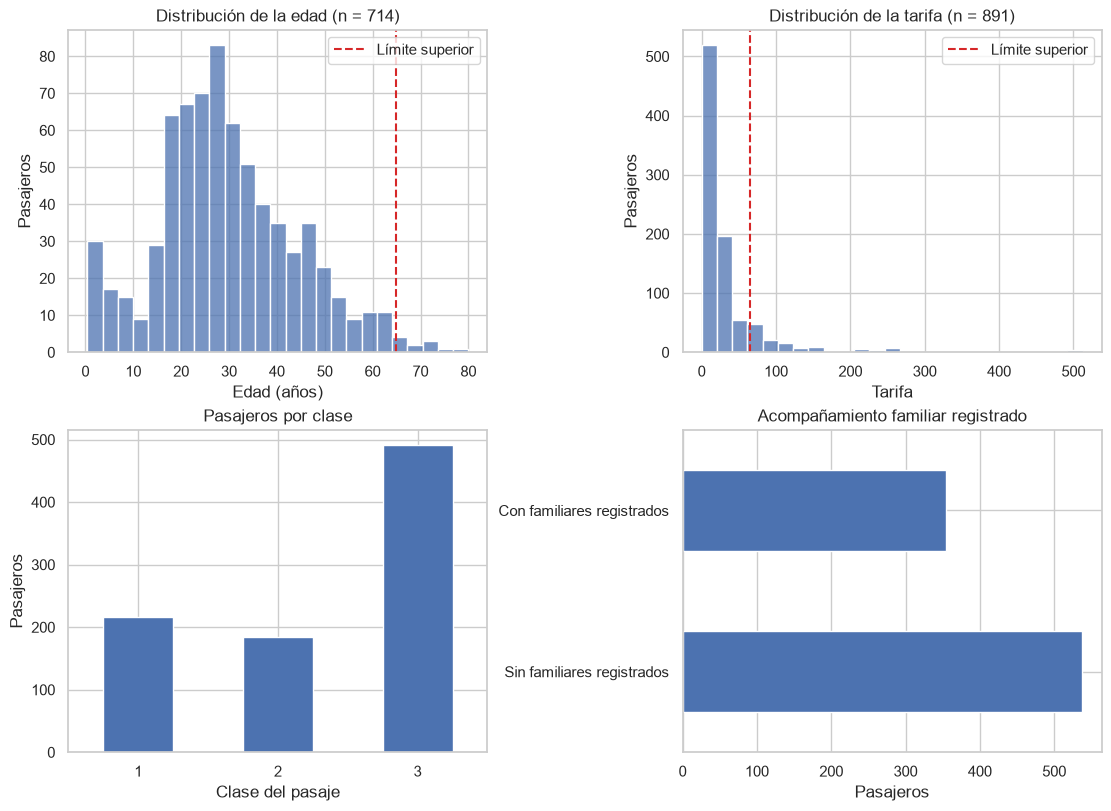

In [7]:
variables_iv = titanic[["age", "fare"]]
n_validos_iv = variables_iv.count()
q1_iv = variables_iv.quantile(0.25)
q3_iv = variables_iv.quantile(0.75)
ric_iv = q3_iv - q1_iv
limite_inferior_iv = q1_iv - 1.5 * ric_iv
limite_superior_iv = q3_iv + 1.5 * ric_iv
atipicos_iv = variables_iv.lt(limite_inferior_iv) | variables_iv.gt(limite_superior_iv)

resumen_iv = pd.DataFrame({
    "n_válido": n_validos_iv,
    "n_faltante": variables_iv.isna().sum(),
    "mínimo": variables_iv.min(),
    "Q1": q1_iv,
    "mediana": variables_iv.median(),
    "media": variables_iv.mean(),
    "Q3": q3_iv,
    "máximo": variables_iv.max(),
    "RIC": ric_iv,
    "desv_est": variables_iv.std(),
    "límite inferior": limite_inferior_iv,
    "límite superior": limite_superior_iv,
    "n fuera de límites": atipicos_iv.sum(),
})
display(resumen_iv.round(2))

TASA_BASE = 100 * titanic["survived"].mean()

conteo_supervivencia_iv = (
    titanic["survived"].value_counts().sort_index()
    .rename(index={0: "No sobrevivió", 1: "Sobrevivió"})
)
conteo_clase_iv = titanic["pclass"].value_counts().sort_index()
conteo_acompanamiento_iv = (
    titanic["alone"].value_counts().reindex([True, False])
    .rename(index={True: "Sin familiares registrados", False: "Con familiares registrados"})
)

for nombre, conteo in [
    ("Supervivencia (línea base)", conteo_supervivencia_iv),
    ("Clase del pasaje", conteo_clase_iv),
    ("Acompañamiento familiar", conteo_acompanamiento_iv),
]:
    display(pd.DataFrame({
        "n": conteo,
        "% del total": (100 * conteo / len(titanic)).round(1),
    }).rename_axis(nombre))

# Anomalía de tarifa detectada en III.5: el límite inferior del RIC es negativo,
# así que la regla no marca los ceros. Se caracterizan aparte.
tarifas_cero_iv = titanic.loc[titanic["fare"] == 0]
print(f"Pasajeros con tarifa 0: {len(tarifas_cero_iv)} de {len(titanic)}")
print("  por clase       :", tarifas_cero_iv["pclass"].value_counts().sort_index().to_dict())
print("  por sexo        :", tarifas_cero_iv["sex"].value_counts().to_dict())
print("  puerto          :", tarifas_cero_iv["embarked"].value_counts(dropna=False).to_dict())
print("  viajaban solos  :", int(tarifas_cero_iv["alone"].sum()), "de", len(tarifas_cero_iv))
print(f"  tasa de supervivencia: {tarifas_cero_iv['survived'].mean() * 100:.1f} %"
      f" ({int(tarifas_cero_iv['survived'].sum())} de {len(tarifas_cero_iv)})")

fig_iv, ejes_iv = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
for eje, variable, titulo, etiqueta in [
    (ejes_iv[0, 0], "age", "Distribución de la edad", "Edad (años)"),
    (ejes_iv[0, 1], "fare", "Distribución de la tarifa", "Tarifa"),
]:
    sns.histplot(data=titanic, x=variable, bins=25, ax=eje)
    eje.axvline(limite_superior_iv[variable], color="tab:red", linestyle="--", label="Límite superior")
    eje.set(title=f"{titulo} (n = {n_validos_iv[variable]})", xlabel=etiqueta, ylabel="Pasajeros")
    eje.legend()

conteo_clase_iv.plot.bar(ax=ejes_iv[1, 0], rot=0)
ejes_iv[1, 0].set(title="Pasajeros por clase", xlabel="Clase del pasaje", ylabel="Pasajeros")
conteo_acompanamiento_iv.plot.barh(ax=ejes_iv[1, 1])
ejes_iv[1, 1].set(title="Acompañamiento familiar registrado", xlabel="Pasajeros", ylabel="")
plt.show()

**Resultados e interpretación preliminar**

- **Supervivencia (línea base).** Sobreviven 342 de 891 pasajeros (38,4 %). Es la referencia contra la cual se leen las tasas por grupo de la sección VI: una tasa muy por encima o por debajo de 38,4 % señala que ese grupo está sobre o subrepresentado entre quienes sobrevivieron.
- **Edad.** La mediana es 28 años y la media 29,70, con desviación estándar 14,53; ambas medidas de centro casi coinciden, lo que indica una distribución bastante simétrica. El 50 % central de las edades registradas se sitúa entre 20,12 y 38 años. La regla del RIC marca 11 observaciones en la cola superior. El resumen usa 714 registros y deja fuera 177 sin edad.
- **Tarifa.** La mediana es 14,45 y la media 32,20, con desviación estándar 49,69. Que la media más que duplique a la mediana y que la desviación supere a la media confirma numéricamente la cola derecha que muestra el histograma. La regla del RIC marca 116 observaciones por encima de 65,63. Su frecuencia describe la forma de la distribución y por sí sola no indica errores de registro.
- **Tarifas registradas en 0.** Los 15 casos detectados en III.5 no quedan marcados por la regla del RIC, porque su límite inferior es negativo. Al caracterizarlos aparecen muy homogéneos: son todos hombres, todos embarcaron en Southampton y todos viajaban sin familiares registrados, repartidos entre las tres clases (5, 6 y 4). Sobrevive 1 de 15 (6,7 %), frente al 38,4 % general. Un perfil tan uniforme es más compatible con un registro sistemático, como pasajes no pagados, que con errores de captura aislados. No se modifican en esta fase y su origen queda pendiente para la revisión de calidad de la Fase 2.
- **Clase.** La tercera reúne 491 pasajeros (55,1 %), frente a 216 en primera (24,2 %) y 184 en segunda (20,7 %). Esta diferencia de tamaños importa al comparar grupos.
- **Acompañamiento familiar.** Hay 537 pasajeros sin familiares registrados (60,3 %) y 354 con familiares registrados (39,7 %). La sección VI.3 compara la supervivencia usando tasas y tamaños de grupo, tanto por tamaño del grupo familiar como por sexo.

## V. Decisiones y transformaciones iniciales
A partir del diagnóstico de la sección III, aquí se analiza el patrón de los faltantes (pregunta 5), se documentan las decisiones adoptadas y se construye la tabla de trabajo `titanic_eda`. El dataset original (`titanic`) no se modifica.

#### V.1 Patrón de los valores faltantes (pregunta 5)
- **Pregunta:** ¿los faltantes de `age` y `deck` se concentran en ciertos grupos?
- **Acción:** se calcula el porcentaje de faltantes de `age` y `deck` dentro de cada categoría de `pclass`, `sex`, `survived` y `embarked`.
- **Decisión y por qué:** se comparan porcentajes dentro de cada grupo y no conteos, porque los grupos tienen tamaños muy distintos (por ejemplo, 491 pasajeros en tercera clase y 184 en segunda).

In [8]:
indicadores = titanic.assign(age_faltante=titanic["age"].isna(), deck_faltante=titanic["deck"].isna())

tablas = []
for var in ["pclass", "sex", "survived", "embarked"]:
    t = indicadores.groupby(var, dropna=False).agg(
        n=("age_faltante", "size"),
        pct_age_faltante=("age_faltante", "mean"),
        pct_deck_faltante=("deck_faltante", "mean"),
    )
    t[["pct_age_faltante", "pct_deck_faltante"]] = (t[["pct_age_faltante", "pct_deck_faltante"]] * 100).round(1)
    t.index = pd.MultiIndex.from_product([[var], t.index.astype(str)], names=["variable", "categoria"])
    tablas.append(t)

patron_faltantes = pd.concat(tablas)
patron_faltantes

n  pct_age_faltante  pct_deck_faltante
variable categoria                                          
pclass   1          216              13.9               19.0
         2          184               6.0               91.3
         3          491              27.7               97.6
sex      female     314              16.9               69.1
         male       577              21.5               81.6
survived 0          549              22.8               87.8
         1          342              15.2               60.2
embarked C          168              22.6               58.9
         Q           77              63.6               94.8
         S          644              14.0               80.1
         nan          2               0.0                0.0

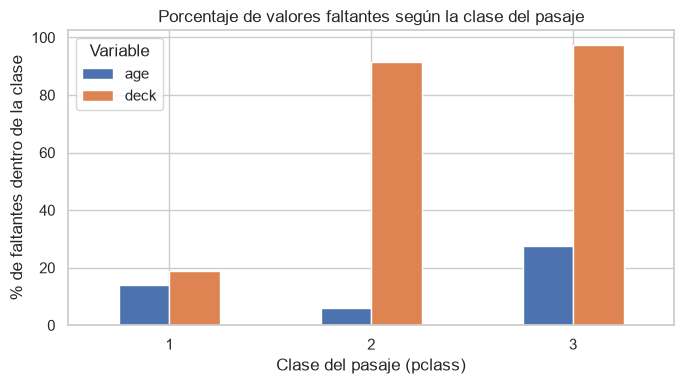

In [9]:
pct_por_clase = indicadores.groupby("pclass")[["age_faltante", "deck_faltante"]].mean() * 100

ax = pct_por_clase.rename(columns={"age_faltante": "age", "deck_faltante": "deck"}).plot.bar(figsize=(7, 4), rot=0)
ax.set_title("Porcentaje de valores faltantes según la clase del pasaje")
ax.set_xlabel("Clase del pasaje (pclass)")
ax.set_ylabel("% de faltantes dentro de la clase")
ax.legend(title="Variable")
plt.tight_layout()
plt.show()

- **Resultado:** los faltantes no se distribuyen de forma pareja.
  - En `age` faltan el 27,7 % de los registros de tercera clase, frente al 13,9 % en primera y al 6,0 % en segunda. La ausencia es mayor entre quienes embarcaron en Queenstown (63,6 %) y entre quienes no sobrevivieron (22,8 % frente a 15,2 %).
  - En `deck` faltan el 97,6 % de los registros de tercera clase y el 91,3 % de segunda, frente al 19,0 % en primera. En la práctica, la cubierta se registró casi solo para primera clase.

  La frecuencia de faltantes varía entre grupos observados. Este avance describe ese patrón sin identificar formalmente el mecanismo de ausencia. Eliminar registros incompletos o imputar un valor único podría cambiar la composición de los grupos.

#### V.2 Decisiones adoptadas

| Aspecto | Decisión | Justificación |
|---|---|---|
| Filas idénticas (107) | **Se conservan** | No hay identificador de pasajero. Con solo 15 columnas, dos pasajeros distintos de perfil común (por ejemplo, hombres de tercera clase, sin edad registrada y con la misma tarifa) pueden tener filas idénticas; eliminarlas reduciría artificialmente esos perfiles. |
| `age` (177 faltantes) | **No se imputa** en esta fase; se agrega el indicador `age_missing` | El patrón de V.1 muestra que la ausencia se asocia con la clase y la supervivencia. Imputar con un valor único deformaría la distribución de la edad. Los análisis de edad usarán los casos disponibles, declarándolo. La imputación se evaluará en la fase de limpieza (Sumativa 2). |
| `deck` (688 faltantes) | **No se imputa**; se conserva y se agrega el indicador `deck_known` | Con un 77,2 % de faltantes, concentrados en segunda y tercera clase, cualquier imputación sería mayoritariamente inventada. Se mantiene solo como variable descriptiva de primera clase. |
| `embarked` (2 faltantes) | **Se mantiene como faltante** | Representa el 0,2 % de los registros y no altera los resultados; se excluyen solo en los análisis que usen el puerto. |
| Columnas redundantes | **Se excluyen de la tabla de trabajo** `class`, `alive`, `embark_town`, `adult_male` y `who` | Se verificó en III.5 que replican otras columnas. `who` además oculta los faltantes de edad, porque clasifica como adultos a quienes no tienen edad registrada. `alone` se conserva porque la usa la pregunta 4. |
| Tipos de datos | `sex`, `embarked` y `deck` pasan a categóricas; `pclass` pasa a categórica ordenada (1 < 2 < 3) | Refleja su tipo analítico (diccionario de III.2) y evita tratarlas como números o texto libre. `survived` se mantiene como 0/1 para que su media sea directamente la tasa de supervivencia. |
| Valores atípicos (`fare`, `sibsp`) | **No se modifican** en esta sección | Son valores plausibles (III.5). Su análisis con la regla IQR corresponde a la sección IV. |

#### V.3 Transformaciones y variables derivadas
- **Pregunta:** ¿cómo dejar una tabla de trabajo coherente con las decisiones anteriores, sin alterar los datos originales?
- **Acción:** se crea `titanic_eda` como copia de `titanic`, se eliminan las columnas redundantes, se ajustan los tipos y se agregan tres variables derivadas:
  - `family_size = sibsp + parch + 1`: número de personas del grupo familiar a bordo, incluido el pasajero. Resume en una sola variable la información de acompañantes (pregunta 4).
  - `age_missing`: `True` si no se registró la edad. Permite seguir analizando a esos pasajeros sin imputar.
  - `deck_known`: `True` si se registró la cubierta. Resume una variable con un 77 % de faltantes.
- **Decisión y por qué:** se trabaja sobre una copia para que el original siga disponible y cualquier transformación pueda rehacerse. Se incluyen validaciones (`assert`) para que el notebook se detenga si alguna transformación no produce lo esperado.

In [10]:
COLUMNAS_REDUNDANTES = ["class", "alive", "embark_town", "adult_male", "who"]

titanic_eda = titanic.drop(columns=COLUMNAS_REDUNDANTES).copy()

# Tipos según su naturaleza analítica
titanic_eda["pclass"] = pd.Categorical(titanic_eda["pclass"], categories=[1, 2, 3], ordered=True)
for col in ["sex", "embarked", "deck"]:
    titanic_eda[col] = titanic_eda[col].astype("category")

# Variables derivadas
titanic_eda["family_size"] = titanic_eda["sibsp"] + titanic_eda["parch"] + 1
titanic_eda["age_missing"] = titanic_eda["age"].isna()
titanic_eda["deck_known"] = titanic_eda["deck"].notna()

# Validaciones
assert titanic.shape == (891, 15), "El dataset original no debe modificarse."
assert len(titanic_eda) == len(titanic), "No se deben eliminar filas."
assert titanic_eda["alone"].eq(titanic_eda["family_size"] == 1).all(), "family_size no es coherente con alone."
assert titanic_eda["age_missing"].sum() == titanic["age"].isna().sum()

print("Original     :", titanic.shape)
print("Tabla trabajo:", titanic_eda.shape)
titanic_eda.info()

Original     : (891, 15)
Tabla trabajo: (891, 13)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    category
 2   sex          891 non-null    category
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    category
 8   deck         203 non-null    category
 9   alone        891 non-null    bool    
 10  family_size  891 non-null    int64   
 11  age_missing  891 non-null    bool    
 12  deck_known   891 non-null    bool    
dtypes: bool(3), category(4), float64(2), int64(4)
memory usage: 48.2 KB


In [11]:
print("Distribución de family_size:")
print(titanic_eda["family_size"].value_counts().sort_index().to_string())

print("\nTasa de supervivencia según disponibilidad del dato:")
tasas_v3 = pd.concat(
    {ind: titanic_eda.groupby(ind)["survived"].agg(n="size", tasa_supervivencia_pct="mean").rename_axis("valor")
     for ind in ["age_missing", "deck_known"]},
    names=["indicador"],
)
tasas_v3["tasa_supervivencia_pct"] = (100 * tasas_v3["tasa_supervivencia_pct"]).round(1)
display(tasas_v3)

Distribución de family_size:
family_size
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7

Tasa de supervivencia según disponibilidad del dato:


n  tasa_supervivencia_pct
indicador   valor                             
age_missing False  714                    40.6
            True   177                    29.4
deck_known  False  688                    29.9
            True   203                    67.0

- **Resultado:** la tabla de trabajo `titanic_eda` conserva los 891 pasajeros y queda con 13 columnas (10 originales y 3 derivadas); el dataset original permanece intacto (891 × 15).
  - `family_size` va de 1 a 11; 537 pasajeros (60,3 %) viajaban solos, lo que coincide con `alone`.
  - La tasa de supervivencia es menor entre quienes no tienen edad registrada (29,4 % frente a 40,6 %) y mucho mayor entre quienes tienen cubierta registrada (67,0 % frente a 29,9 %). Esto último refleja, probablemente, que la cubierta se registró casi solo en primera clase, más que un efecto propio de la cubierta. Estas diferencias son descriptivas y no implican causalidad.
- **Uso en las secciones siguientes:** la sección VI puede trabajar sobre `titanic_eda`; los análisis de `age` deben declarar que excluyen los 177 registros sin edad.

## VI. Resultados e interpretación inicial
Resultados de esta primera implementación y su interpretación breve, relacionados con las preguntas exploratorias: pregunta 2 (VI.1), pregunta 3 (VI.2) y pregunta 4 (VI.3). Siguiendo el apunte del curso (Paraíso, 2026), cada tabla deja visible el denominador: la tasa y el número de pasajeros (n) de cada grupo.

#### VI.1 Supervivencia por sexo y clase (pregunta 2)
- **Pregunta:** ¿cambia la supervivencia según el sexo y la clase del pasaje?
- **Acción:** se calcula la tasa de supervivencia agrupando `titanic_eda` por `pclass` y `sex`, y se visualiza con un gráfico de barras agrupadas.
- **Decisión y por qué:** se usa la tasa (media de `survived`) y no el conteo absoluto, porque los grupos tienen tamaños muy distintos (por ejemplo, hay muchos más hombres de tercera clase que mujeres de primera). Se trabaja sobre `titanic_eda`, que ya tiene `pclass` como categórica ordenada y `sex` como categórica (sección V); el dataset original no se modifica.

In [12]:
tasa_sexo_clase = (
    titanic_eda.groupby(["pclass", "sex"], observed=True)["survived"]
    .agg(n="size", n_sobrevivientes="sum", tasa_supervivencia="mean")
)
tasa_sexo_clase["tasa_supervivencia"] = (tasa_sexo_clase["tasa_supervivencia"] * 100).round(1)
tasa_sexo_clase

n  n_sobrevivientes  tasa_supervivencia
pclass sex                                              
1      female   94                91                96.8
       male    122                45                36.9
2      female   76                70                92.1
       male    108                17                15.7
3      female  144                72                50.0
       male    347                47                13.5

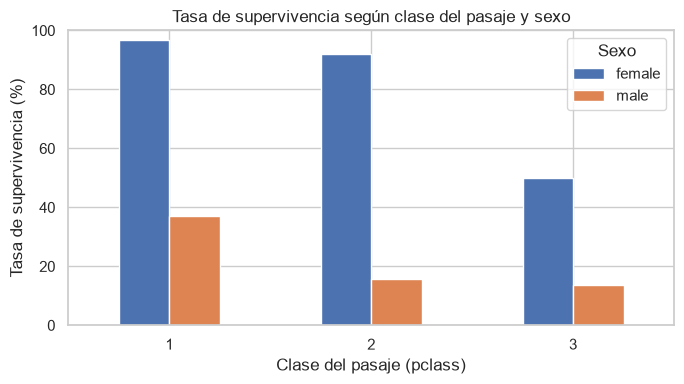

In [13]:
tabla_plot = tasa_sexo_clase["tasa_supervivencia"].unstack("sex")

ax = tabla_plot.plot.bar(figsize=(7, 4), rot=0)
ax.set_title("Tasa de supervivencia según clase del pasaje y sexo")
ax.set_xlabel("Clase del pasaje (pclass)")
ax.set_ylabel("Tasa de supervivencia (%)")
ax.set_ylim(0, 100)
ax.legend(title="Sexo")
plt.tight_layout()
plt.show()

- **Resultado:** la tasa observada es mayor entre las mujeres en las tres clases. En primera clase sobreviven 91 de 94 mujeres (96,8 %) y 45 de 122 hombres (36,9 %). En segunda sobreviven 70 de 76 mujeres (92,1 %) y 17 de 108 hombres (15,7 %). En tercera sobreviven 72 de 144 mujeres (50,0 %) y 47 de 347 hombres (13,5 %). La mayor brecha por sexo se observa en segunda clase (unos 76 puntos porcentuales). Entre primera y tercera clase la diferencia de tasas es de 46,8 puntos porcentuales en mujeres y 23,4 en hombres. Son comparaciones descriptivas dentro del dataset.

#### VI.2 Relación entre la edad y la supervivencia (pregunta 3)
- **Pregunta:** ¿cómo se relaciona la edad con la supervivencia?
- **Acción:** se comparan la media, la mediana y la dispersión de `age` entre quienes sobrevivieron y quienes no, y se visualiza la distribución con un diagrama de caja. Después se corta la edad en tramos y se calcula la tasa de supervivencia y el n de cada tramo.
- **Decisión y por qué:** se excluyen los 177 registros sin `age` en lugar de imputarlos, siguiendo la decisión de la sección V de no imputar esta variable en esta fase; se usa el indicador `age_missing` de `titanic_eda` para filtrarlos de forma explícita, en vez de volver a calcular los faltantes. Se añade el corte por tramos porque un resumen de centro puede ocultar diferencias concentradas en las colas: si las medianas coinciden, la comparación por tramos muestra si la edad importa en algún rango concreto. Los cortes (12, 18, 40 y 60 años) separan infancia, adolescencia, adultez y vejez; son convencionales y se fijan antes de mirar las tasas.

In [14]:
con_edad = titanic_eda.loc[~titanic_eda["age_missing"]]

resumen_edad_supervivencia = con_edad.groupby("survived")["age"].agg(
    n="size", minimo="min", q1=lambda s: s.quantile(0.25), media="mean",
    mediana="median", q3=lambda s: s.quantile(0.75), maximo="max", desv_est="std",
).round(1)
print(f"Registros excluidos por no tener age: {titanic_eda['age_missing'].sum()}")
display(resumen_edad_supervivencia)

tramos_edad = pd.cut(
    con_edad["age"], bins=[0, 12, 18, 40, 60, 100],
    labels=["0 a 12", "13 a 18", "19 a 40", "41 a 60", "61 o más"],
)
tasa_tramo_edad = (
    con_edad.groupby(tramos_edad, observed=True)["survived"]
    .agg(n="size", tasa_supervivencia="mean")
)
tasa_tramo_edad["tasa_supervivencia"] = (tasa_tramo_edad["tasa_supervivencia"] * 100).round(1)
tasa_tramo_edad["dif_vs_base_pp"] = (tasa_tramo_edad["tasa_supervivencia"] - TASA_BASE).round(1)
tasa_tramo_edad

Registros excluidos por no tener age: 177


,n,minimo,q1,media,mediana,q3,maximo,desv_est
survived,,,,,,,,
0,424,1.0,21.0,30.6,28.0,39.0,74.0,14.2
1,290,0.4,19.0,28.3,28.0,36.0,80.0,15.0


,n,tasa_supervivencia,dif_vs_base_pp
age,,,
0 a 12,69,58.0,19.6
13 a 18,70,42.9,4.5
19 a 40,425,38.8,0.4
41 a 60,128,39.1,0.7
61 o más,22,22.7,-15.7


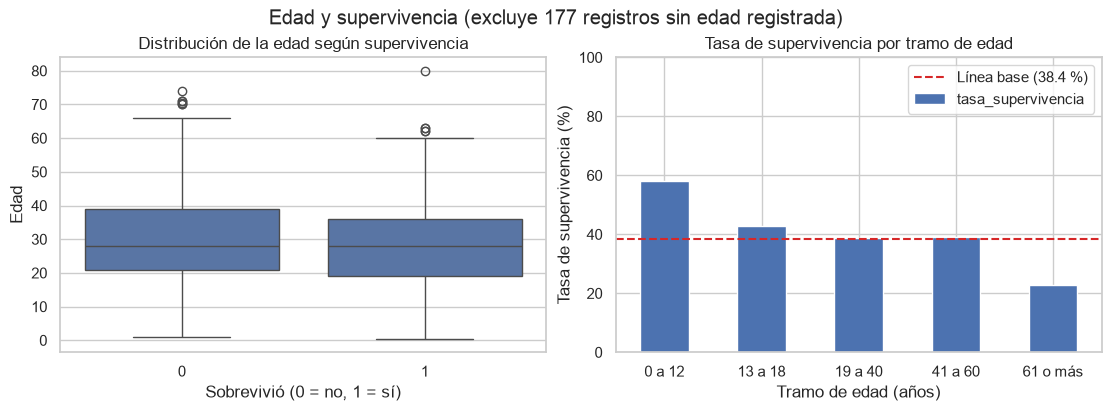

In [15]:
fig_vi2, ejes_vi2 = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

sns.boxplot(data=con_edad, x="survived", y="age", ax=ejes_vi2[0])
ejes_vi2[0].set(title="Distribución de la edad según supervivencia",
                xlabel="Sobrevivió (0 = no, 1 = sí)", ylabel="Edad")

tasa_tramo_edad["tasa_supervivencia"].plot.bar(ax=ejes_vi2[1], rot=0)
ejes_vi2[1].axhline(TASA_BASE, color="tab:red", linestyle="--",
                    label=f"Línea base ({TASA_BASE:.1f} %)")
ejes_vi2[1].set(title="Tasa de supervivencia por tramo de edad",
                xlabel="Tramo de edad (años)", ylabel="Tasa de supervivencia (%)", ylim=(0, 100))
ejes_vi2[1].legend()

fig_vi2.suptitle("Edad y supervivencia (excluye 177 registros sin edad registrada)")
plt.show()

- **Resultado:** las distribuciones de edad son similares entre quienes sobrevivieron y quienes no, considerando solo los 714 registros con edad conocida.
  - Entre quienes no sobrevivieron (n = 424 con edad registrada), la edad va de 1,0 a 74,0 años, con media 30,6 (mediana 28,0; Q1–Q3: 21,0–39,0; desviación 14,2).
  - Entre quienes sobrevivieron (n = 290), la edad va de 0,4 a 80,0 años, con media 28,3 (mediana 28,0; Q1–Q3: 19,0–36,0; desviación 15,0).
  - Las medianas coinciden y los intervalos entre Q1 y Q3 se superponen ampliamente. Las medias difieren en 2,3 años.
- **Por tramos de edad la lectura cambia.** Que las distribuciones marginales se parezcan no implica que la edad sea indiferente: el efecto está en las colas, donde hay pocos casos y el centro no lo refleja.
  - Sobrevive el 58,0 % de los 69 niños de 0 a 12 años, 19,6 puntos porcentuales sobre la línea base de 38,4 % (IV).
  - En el extremo opuesto, sobrevive el 22,7 % de los 22 pasajeros de 61 años o más, 15,7 puntos por debajo de la línea base.
  - Los tres tramos intermedios se mueven entre 38,8 % y 42,9 %, muy cerca de la base, y concentran 623 de los 714 registros con edad. Por eso las medianas coinciden.
  - El tramo de 61 o más tiene solo 22 pasajeros, así que su tasa debe leerse con cautela. La comparación es descriptiva y no se controla por sexo ni por clase, lo que queda para la fase siguiente.

#### VI.3 Viajar con familiares registrados y supervivencia (pregunta 4)
- **Pregunta:** ¿viajar con familiares registrados se asocia con sobrevivir?
- **Acción:** se agrupa `family_size` (que resume `sibsp` y `parch`) en tres tramos (viaja solo, 2 a 4 personas, 5 o más), se calcula la tasa de supervivencia de cada tramo y se contrasta por sexo usando `alone`.
- **Decisión y por qué:** se agrupa `family_size` porque los grupos grandes son pequeños (entre 6 y 22 pasajeros por tamaño) y sus tasas individuales serían inestables. Se usa la tasa y no el conteo, por el distinto tamaño de los grupos. Se contrasta por sexo porque es la variable más asociada a la supervivencia (VI.1) y podría confundir la lectura.

,n,tasa_supervivencia
family_size,,
1 (viaja solo),537,30.4
2 a 4,292,57.9
5 o más,62,16.1


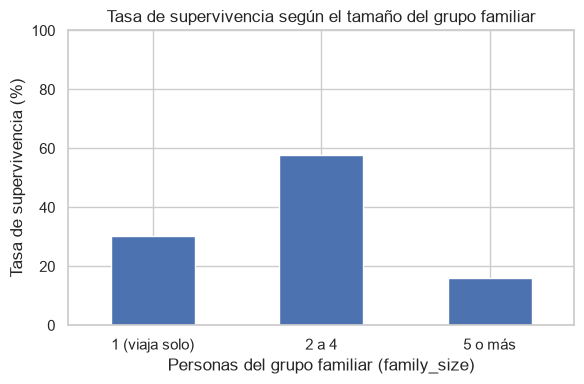

In [16]:
grupo_familiar = pd.cut(
    titanic_eda["family_size"], bins=[0, 1, 4, 11],
    labels=["1 (viaja solo)", "2 a 4", "5 o más"],
)
tasa_acompanantes = (
    titanic_eda.groupby(grupo_familiar, observed=True)["survived"]
    .agg(n="size", tasa_supervivencia="mean")
)
tasa_acompanantes["tasa_supervivencia"] = (tasa_acompanantes["tasa_supervivencia"] * 100).round(1)
display(tasa_acompanantes)

ax = tasa_acompanantes["tasa_supervivencia"].plot.bar(figsize=(6, 4), rot=0)
ax.set_title("Tasa de supervivencia según el tamaño del grupo familiar")
ax.set_xlabel("Personas del grupo familiar (family_size)")
ax.set_ylabel("Tasa de supervivencia (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

In [17]:
tasa_sexo_solo = (
    titanic_eda.groupby(["sex", "alone"], observed=True)["survived"]
    .agg(n="size", tasa_supervivencia="mean")
)
tasa_sexo_solo["tasa_supervivencia"] = (tasa_sexo_solo["tasa_supervivencia"] * 100).round(1)
tasa_sexo_solo

n  tasa_supervivencia
sex    alone                         
female False  188                71.3
       True   126                78.6
male   False  166                27.1
       True   411                15.6

- **Resultado:** la tasa observada es mayor en grupos familiares de 2 a 4 personas que entre quienes viajaban solos o en grupos más grandes.
  -  De quienes viajaban solos sobrevive el 30,4 % (n = 537); en grupos de 2 a 4 personas sobrevive el 57,9 % (n = 292); en grupos de 5 o más, el 16,1 % (n = 62).
  - Al separar por sexo, la lectura cambia: entre las mujeres sobrevive el 71,3 % de las acompañadas (188) frente al 78,6 % de las que viajaban solas (126); entre los hombres, el 27,1 % de los acompañados (166) frente al 15,6 % de los que viajaban solos (411).
  - La mayoría de quienes viajaban solos eran hombres (411 de 537), y el patrón de tasas cambia al separar por sexo. Por ello, la tasa global debe leerse junto con las tasas estratificadas.

  Son diferencias descriptivas; no implican causalidad, y el tramo de 5 o más personas es pequeño, por lo que su tasa debe leerse con cautela.

## VII. Supuestos y limitaciones

- **Proceso.** Se verifica la fuente y se diagnostica la calidad del dataset (III). Luego se exploran las distribuciones originales (IV), se documentan las decisiones de preparación en una copia (V) y se comparan tasas y distribuciones de edad según las preguntas del avance (VI).
- **Supuestos.** Se usa cada fila como unidad de análisis y `survived` como indicador binario. Las tasas se calculan dentro de cada grupo. Se conservan las filas idénticas porque, sin un identificador individual, no se puede saber si representan el mismo pasajero. `alone` describe la ausencia de los familiares registrados por `sibsp` y `parch`; puede haber otros acompañantes fuera de esas categorías.
- **Limitaciones.** El análisis de edad se restringe a 714 de 891 registros. La falta de edad (19,9 %) varía por clase y supervivencia (V.1), por lo que los resultados con edad conocida pueden diferir de los que se obtendrían con los registros completos. La cubierta tiene 688 faltantes (77,2 %), concentrados en segunda y tercera clase. Las tasas de subgrupos pequeños son sensibles a pocos casos. El dataset tampoco incluye variables del proceso de evacuación (ubicación a bordo en el momento del impacto o asignación a botes), de modo que ninguna de las asociaciones observadas puede leerse como el mecanismo que explica la supervivencia. El alcance es descriptivo y las asociaciones observadas no permiten atribuir causas ni extrapolar a pasajeros fuera del dataset.
- **Continuidad.** En la siguiente fase se evaluará la sensibilidad de los resultados de edad a distintos tratamientos de faltantes. También conviene revisar el origen de las 15 tarifas registradas en 0 y el de las tarifas altas por clase (IV), y comparar el patrón de acompañamiento dentro de estratos de sexo y clase, mostrando siempre el tamaño de los grupos.

## VIII. Cierre del avance

**Síntesis.** Se verificó el CSV de referencia con SHA-256 y se revisaron 891 registros y 15 variables. El diagnóstico orientó la construcción de una tabla de trabajo de 891 registros y 13 variables. Se conservaron las filas idénticas y se documentaron las transformaciones. El notebook registra al inicio las versiones usadas y declara sus dependencias en `requirements.txt`.

**Hallazgos de las cinco preguntas**

1. **Distribuciones (IV).** Sobreviven 342 de 891 pasajeros (38,4 %), línea base de todas las comparaciones. La mediana de edad es 28 años entre 714 registros válidos (media 29,70) y la tarifa tiene media 32,20 frente a una mediana de 14,45. Tercera clase reúne 491 de 891 pasajeros y 116 tarifas superan el límite superior de 1,5 × RIC.
2. **Sexo y clase (VI.1).** La tasa observada es mayor entre las mujeres en las tres clases. En primera clase es 96,8 % en mujeres (91/94) y 36,9 % en hombres (45/122).
3. **Edad (VI.2).** La mediana es de 28 años en ambos grupos entre quienes tienen edad registrada (424 no sobrevivientes y 290 sobrevivientes), pero el corte por tramos muestra que la edad sí separa en las colas: 58,0 % de supervivencia entre los 69 niños de 0 a 12 años y 22,7 % entre los 22 pasajeros de 61 o más, frente a una línea base de 38,4 %.
4. **Acompañamiento familiar (VI.3).** La mayor tasa global se observa en grupos de 2 a 4 personas (57,9 %; n = 292). La comparación entre viajar solo o acompañado cambia al separar por sexo.
5. **Faltantes (V.1).** En tercera clase falta la edad en el 27,7 % de los registros y la cubierta en el 97,6 %. Esto acota la interpretación de los análisis con registros completos.

**Variables candidatas para las fases siguientes.** Del diagnóstico y de las comparaciones de este avance se priorizan `sex` y `pclass`, que muestran la mayor separación de tasas (VI.1); `family_size` junto con `alone`, leídas dentro de cada sexo (VI.3); `age` acompañada de `age_missing`, preferentemente por tramos, dado que su efecto se concentra en los extremos (VI.2); y `fare`, con su cola derecha y las 15 tarifas en 0 por revisar (IV). `deck` se descarta como variable explicativa por su 77,2 % de faltantes y se conserva solo a través de `deck_known`; `embarked` queda en observación por el patrón de faltantes de Queenstown (V.1). Las columnas redundantes excluidas en V.3 no se retoman.

**Continuidad.** En la Fase 2 se revisará la sensibilidad al tratamiento de las edades faltantes y se compararán los tramos de edad y el acompañamiento dentro de estratos de sexo y clase, donde los tramos extremos quedan con pocos casos. Los resultados de este avance son descriptivos.

**Referencias del análisis.** El enfoque de EDA mínimo viable del material del curso (Paraíso, 2026) orienta la exploración de IV y el registro de decisiones de V. El criterio de 1,5 × RIC usado en IV se documenta en Bruce et al. (2020). La estructura del notebook (introducción, descripción del dataset, preparación, EDA y resultados) y el registro de versiones, entradas, salidas y decisiones siguen el recurso *Checklist de notebook reproducible* (Universidad Andrés Bello, 2026a) y el notebook *EDA mínimo viable* (Universidad Andrés Bello, 2026b), materiales de la Semana 1 del curso. Las referencias completas figuran en el [informe complementario](../docs/informe_sumativo1/mcdi503_f1_sumativo_grupo4.pdf).